# code_180 · Recommendation needs exposure as well as preference

**Book:** section 34.3. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_34_GUIDE.md), [execution evidence](../CHAPTER_34_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_180).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Target semantics, censoring or exposure, information roles and independent assessment are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7580;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7580


<a id="observed-interactions-and-cold-assets"></a>
 ## Learn from the interactions that were actually logged
 Treat 128 warm asset profiles as users and 32 maintenance-option descriptions as items. Twenty-four additional asset profiles are cold: they supply visible features but no fitting interactions. Four visible features on each side generate a fixed response-propensity matrix. A response represents acceptance of an option, not its effect on failure. Six thousand source requests select warm assets uniformly and options from a known popularity-biased distribution. Only these observed binary responses enter fitting. Repeating an option is permitted; evaluation predicts responses to a new request on the same warm population, or a new cold asset, rather than claiming novel-item generalization.

 Fit 8-dimensional matrix factorization and a one-hop LightGCN-style model with normalized bipartite propagation, layer averaging and BPR gradients through the propagation. Positive edges come exclusively from source positive responses. BPR samples options without a source positive edge, which mixes unseen options and observed nonresponses; treating them as less preferred is a training assumption, not an observed dislike. Both models receive identical 600 batches of 256 triples and the same initial embeddings. A feature-based 4→16→8 two-tower model instead fits the observed Bernoulli responses for 600 updates. ID-based models use an explicit source-popularity fallback for cold profiles. No oracle propensity enters fitting or checkpoint choice.


,model,population,utility_NDCG_at5,expected_top1_response
0,Popularity,Warm,0.698063,0.609139
1,Popularity,Cold,0.703472,0.594022
2,MF,Warm,0.744534,0.608717
3,MF,Cold,0.703472,0.594022
4,Graph,Warm,0.762738,0.639534
5,Graph,Cold,0.703472,0.594022
6,Two tower,Warm,0.989490,0.853646
7,Two tower,Cold,0.986247,0.839528


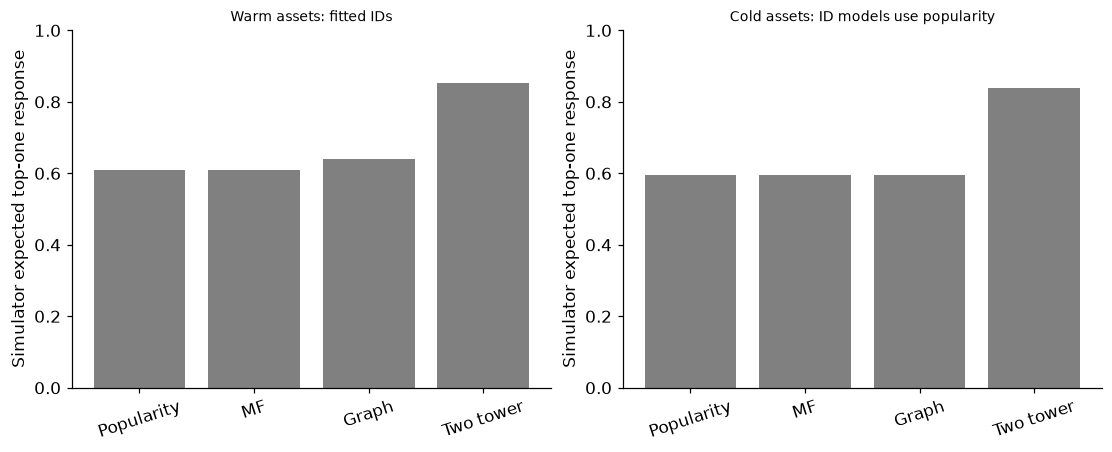

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
warm=128;cold=24;items=32;uf=rng.normal(size=(warm+cold,4));it=rng.normal(size=(items,4));latent=uf@it.T/2+.25*it[:,0][None,:];truth=1/(1+np.exp(-latent));lp=np.exp(np.linspace(-1.5,1.5,items));lp/=lp.sum();u=rng.integers(warm,size=6000);a=rng.choice(items,size=6000,p=lp);y=(rng.random(6000)<truth[u,a]).astype(int);edges=np.zeros((warm,items),bool);edges[u[y==1],a[y==1]]=True;pu,pa=np.where(edges);negatives=[np.flatnonzero(~edges[j]) for j in range(warm)];assert all(len(n)>0 for n in negatives)
A=np.zeros((warm+items,warm+items));A[:warm,warm:]=edges;A[warm:,:warm]=edges.T;degree=A.sum(1);inv=np.divide(1,np.sqrt(degree),out=np.zeros_like(degree),where=degree>0);P=torch.tensor(inv[:,None]*A*inv[None,:]);initial=.1*torch.randn(warm+items,8);trng=np.random.default_rng(SEED+10);batches=[]
for step in range(600):
    chosen=trng.integers(len(pu),size=256);bu=pu[chosen];bp=pa[chosen];bn=np.array([trng.choice(negatives[j]) for j in bu]);batches.append((torch.tensor(bu),torch.tensor(bp),torch.tensor(bn)))
learned={};training_losses={}
for name in ['MF','Graph']:
    emb=nn.Parameter(initial.clone());opt=torch.optim.Adam([emb],lr=.03)
    for bu,bp,bn in batches:
        z=emb if name=='MF' else (emb+P@emb)/2;positive=(z[bu]*z[warm+bp]).sum(1);negative=(z[bu]*z[warm+bn]).sum(1);loss=nn.functional.softplus(negative-positive).mean()+.001*emb.square().mean();opt.zero_grad();loss.backward();opt.step()
    with torch.no_grad():z=emb if name=='MF' else (emb+P@emb)/2;learned[name]=(z[:warm]@z[warm:].T).numpy()
    training_losses[name]=float(loss.detach())
user_tower=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,8));item_tower=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,8));opt=torch.optim.Adam(list(user_tower.parameters())+list(item_tower.parameters()),lr=.01);UF=torch.tensor(uf);IT=torch.tensor(it);src_y=torch.tensor(y,dtype=torch.float64);trng=np.random.default_rng(SEED+20)
for step in range(600):
    ids=trng.integers(len(u),size=256);score=(user_tower(UF[u[ids]])*item_tower(IT[a[ids]])).sum(1)/np.sqrt(8);loss=nn.functional.binary_cross_entropy_with_logits(score,src_y[ids]);opt.zero_grad();loss.backward();opt.step()
with torch.no_grad():tower=(user_tower(UF)@item_tower(IT).T).numpy()/np.sqrt(8)
popularity=np.bincount(a[y==1],minlength=items).astype(float);fallback=np.repeat(popularity[None,:],cold,axis=0);scores={'Popularity':np.repeat(popularity[None,:],warm+cold,axis=0),'MF':np.r_[learned['MF'],fallback],'Graph':np.r_[learned['Graph'],fallback],'Two tower':tower}
def ranking_metrics(score,utility,k=5):
    order=np.argsort(-score,axis=1);disc=1/np.log2(np.arange(2,k+2));dcg=(np.take_along_axis(utility,order[:,:k],axis=1)*disc).sum(1);ideal=(np.sort(utility,axis=1)[:,-k:][:,::-1]*disc).sum(1);return float((dcg/ideal).mean()),float(utility[np.arange(len(utility)),order[:,0]].mean())
rows=[]
for name,score in scores.items():
    for role,sl in [('Warm',slice(0,warm)),('Cold',slice(warm,None))]:
        ndcg,value=ranking_metrics(score[sl],truth[sl]);rows.append({'model':name,'population':role,'utility_NDCG_at5':ndcg,'expected_top1_response':value})
assert np.allclose(P.numpy(),P.numpy().T) and np.sum(edges)>0 and set(u)==set(range(warm));assert np.isfinite(tower).all()
RESULTS.update(warm_assets=warm,cold_assets=cold,options=items,source_requests=len(u),positive_edges=int(edges.sum()),bpr_updates=600,bpr_batch_size=256,graph_propagation_layers=1,tower_updates=600,source_option_probabilities=lp.tolist(),last_BPR_losses=training_losses,final_population_metrics=rows,oracle_used_for_training=False,cold_ID_fallback='source positive-response popularity',repeat_options_permitted=True)
display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(10,4));names=list(scores)
for j,role in enumerate(['Warm','Cold']):
    r=[v for v in rows if v['population']==role];axes[j].bar(range(4),[v['expected_top1_response'] for v in r],color='.5');axes[j].set(xticks=range(4),xticklabels=names,ylim=(0,1),ylabel='Simulator expected top-one response',title='Warm assets: fitted IDs' if role=='Warm' else 'Cold assets: ID models use popularity');axes[j].tick_params(axis='x',rotation=18)
plt.show()


<a id="retrieval-and-reranking"></a>
 ## A reranker cannot choose an option absent from its candidate pool
 Fit a fixed histogram gradient-boosted reranker to the same source observed responses, using asset features, option features and their elementwise interactions. Two-tower scores retrieve eight of 32 options. The reranker scores only those eight. Assess candidate recall against the simulator's best three options, then expected top-one response before and after reranking. These oracle utilities are independent audit quantities; they are not observations available for fitting or evidence of maintenance efficacy. Native reranker settings are fixed:100 iterations, depth 3 and learning rate 0.08.


,population,candidate_recall_top3_in8,tower_expected_top1,reranked_expected_top1,oracle_expected_top1
0,Warm,0.989583,0.853646,0.840889,0.866024
1,Cold,0.972222,0.839528,0.831105,0.851609


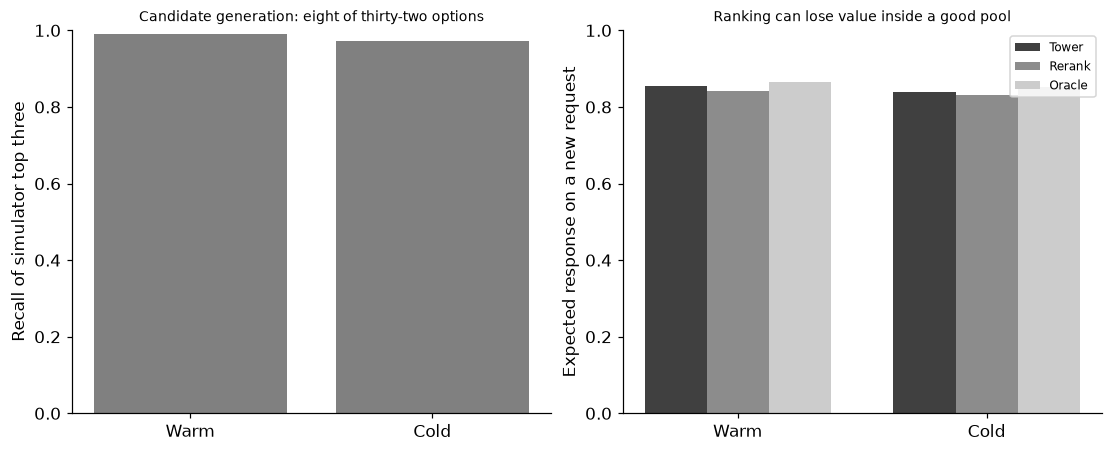

In [3]:
def features(users,actions):return np.c_[uf[users],it[actions],uf[users]*it[actions]]
reranker=HistGradientBoostingClassifier(max_iter=100,max_depth=3,learning_rate=.08,random_state=SEED).fit(features(u,a),y);pools=np.argsort(-tower,axis=1)[:,:8];all_u=np.repeat(np.arange(warm+cold),8);candidate_scores=reranker.predict_proba(features(all_u,pools.ravel()))[:,1].reshape(warm+cold,8);policy=pools[np.arange(warm+cold),np.argmax(candidate_scores,1)];stage_rows=[]
for role,ids in [('Warm',np.arange(warm)),('Cold',np.arange(warm,warm+cold))]:
    best=np.argsort(-truth[ids],axis=1)[:,:3];recall=np.mean([len(set(b)&set(pools[j]))/3 for j,b in zip(ids,best)]);before=float(truth[ids,np.argmax(tower[ids],1)].mean());after=float(truth[ids,policy[ids]].mean());stage_rows.append({'population':role,'candidate_recall_top3_in8':float(recall),'tower_expected_top1':before,'reranked_expected_top1':after,'oracle_expected_top1':float(truth[ids].max(1).mean())})
assert pools.shape==(warm+cold,8) and all(policy[j] in pools[j] for j in range(warm+cold))
RESULTS.update(candidate_pool_size=8,reranker_iterations=100,stage_metrics=stage_rows,reranker_source_requests=len(y))
display(pd.DataFrame(stage_rows));fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(2),[r['candidate_recall_top3_in8'] for r in stage_rows],color='.5');axes[0].set(xticks=range(2),xticklabels=['Warm','Cold'],ylim=(0,1),ylabel='Recall of simulator top three',title='Candidate generation: eight of thirty-two options')
for j,key in enumerate(['tower_expected_top1','reranked_expected_top1','oracle_expected_top1']):axes[1].bar(np.arange(2)+(j-1)*.25,[r[key] for r in stage_rows],width=.25,color=['.25','.55','.8'][j],label=['Tower','Rerank','Oracle'][j])
axes[1].set(xticks=range(2),xticklabels=['Warm','Cold'],ylim=(0,1),ylabel='Expected response on a new request',title='Ranking can lose value inside a good pool');axes[1].legend(fontsize=8);plt.show()


<a id="logged-policy-value-and-feedback"></a>
 ## Assess exposure and feedback without retraining on audit truth
 Two thousand independent warm requests use the same known randomized option assignment, with fresh responses. The frozen reranked policy's match-weighted IPS estimate targets mean response on that request population. Also report the raw matched response mean, self-normalized estimate and weight effective sample size. The simulator supplies expected response under the fixed policy only as an audit. Repeated assets are allowed; this is conditional assessment on a fixed finite asset population, not an asset-independent field interval.

 Separately simulate 80 rounds of 256 requests with fixed preferences. Compare uniform option exposure with 90%positive-count reinforcement plus 10%uniform exploration. Positive response counts update exposure only in this separate process. Record top-five exposure mass and mean response; a self-reinforcing option log need not provide representative alternatives. The feedback experiment neither updates nor validates the earlier recommender.


{'requests': 2000, 'matches': 69, 'raw_match_response': 0.7971014492753623, 'IPS_response': 0.691118015264682, 'self_normalized_response': 0.7319186159976525, 'weight_ESS': 35.89927573294769, 'simulator_policy_response_audit': 0.842188159078858}


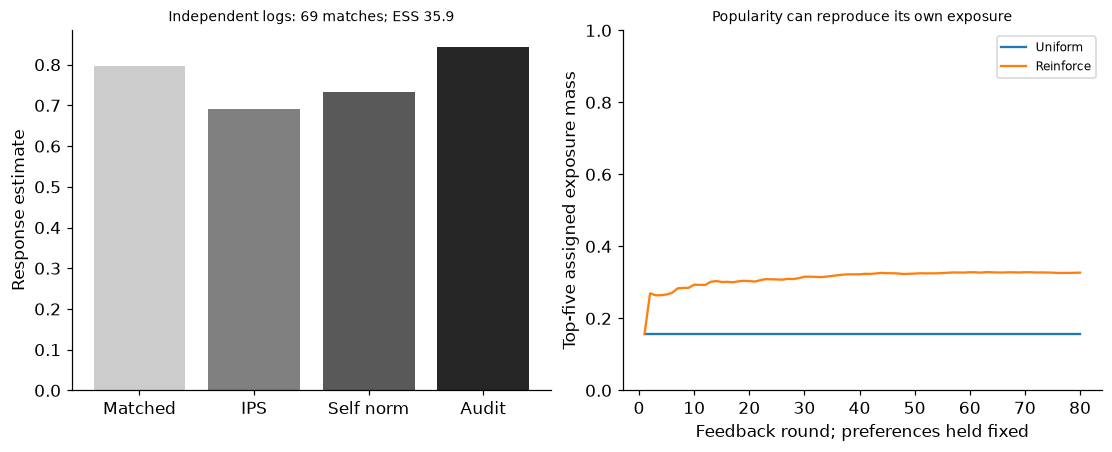

In [4]:
gr=np.random.default_rng(SEED+100);ou=gr.integers(warm,size=2000);oa=gr.choice(items,size=2000,p=lp);oy=(gr.random(2000)<truth[ou,oa]).astype(int);match=oa==policy[ou];weights=match/lp[oa];ips=float(np.mean(weights*oy));sn=float(np.sum(weights*oy)/weights.sum());raw=float(oy[match].mean());ess=float(weights.sum()**2/np.sum(weights**2));audit=float(truth[ou,policy[ou]].mean());assert match.sum()>0 and weights.sum()>0 and np.all(lp>0)
ope={'requests':2000,'matches':int(match.sum()),'raw_match_response':raw,'IPS_response':ips,'self_normalized_response':sn,'weight_ESS':ess,'simulator_policy_response_audit':audit};loop={}
for mode in ['Uniform','Reinforce']:
    gr=np.random.default_rng(SEED+200);counts=np.ones(items);history=[]
    for step in range(80):
        prob=np.ones(items)/items if mode=='Uniform' else .1/items+.9*counts/counts.sum();uu=gr.integers(warm,size=256);aa=gr.choice(items,size=256,p=prob);yy=gr.random(256)<truth[uu,aa];counts+=np.bincount(aa[yy],minlength=items);history.append((float(np.sort(prob)[-5:].sum()),float(yy.mean())))
    loop[mode]=np.array(history)
RESULTS.update(independent_logged_policy=ope,feedback_rounds=80,feedback_requests_per_round=256,feedback_final_top5_mass={k:float(v[-1,0]) for k,v in loop.items()},feedback_mean_response={k:float(v[:,1].mean()) for k,v in loop.items()},feedback_preferences_fixed=True,feedback_used_to_fit_prior_models=False)
print(ope);fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(4),[raw,ips,sn,audit],color=['.8','.5','.35','.15']);axes[0].set(xticks=range(4),xticklabels=['Matched','IPS','Self norm','Audit'],ylabel='Response estimate',title=f'Independent logs: {int(match.sum())} matches; ESS {ess:.1f}')
for name,v in loop.items():axes[1].plot(np.arange(1,81),v[:,0],label=name)
axes[1].set(xlabel='Feedback round; preferences held fixed',ylabel='Top-five assigned exposure mass',ylim=(0,1),title='Popularity can reproduce its own exposure');axes[1].legend(fontsize=8);plt.show()


In [5]:
summary={'example_id':'code_180','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual matrix factorization and one-hop normalized graph BPR training', 'feature-based two-tower retrieval with observed-response likelihood', 'cold-entity fallback and separate candidate recall versus reranking', 'known-propensity independent logged policy assessment', 'fixed-preference exposure reinforcement simulation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual matrix factorization and one-hop normalized graph BPR training", "feature-based two-tower retrieval with observed-response likelihood", "cold-entity fallback and separate candidate recall versus reranking", "known-propensity independent logged policy assessment", "fixed-preference exposure reinforcement simulation"], "elapsed_seconds": 1.324, "example_id": "code_180", "hardware": "Darwin arm64 CPU", "results": {"bpr_batch_size": 256, "bpr_updates": 600, "candidate_pool_size": 8, "cold_ID_fallback": "source positive-response popularity", "cold_assets": 24, "feedback_final_top5_mass": {"Reinforce": 0.32685178671918963, "Uniform": 0.15625}, "feedback_mean_response": {"Reinforce": 0.5259765625, "Uniform": 0.499365234375}, "feedback_preferences_fixed": true, "feedback_requests_per_round": 256, "feedback_rounds": 80, "feedback_used_to_fit_prior_models": false, "final_population_metrics": [{"expected_top1_response": 0.6091390371406324,